# China-made cars and Mexico's 50% tariff

**Role:** analyst at the Secretaría de Economía, briefing the Subsecretaría de Industria y Comercio.

**Question:** since 1 January 2026, light vehicles from countries without a trade agreement with Mexico pay up to 50%. China is the biggest of those countries. Did the tariff slow the sale of China-made cars?

**Short answer:** not yet. Every month of 2026 so far has a higher China-made share than the same month of 2025, and March 2026 is the highest month on record.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display

# Draw charts as vector graphics (SVG): lines and text stay sharp at any zoom
%config InlineBackend.figure_format = "svg"

# Inter, the dashboard's font, shipped in fonts/ so the charts look the same on any computer
for f in Path("fonts").glob("*.ttf"):
    font_manager.fontManager.addfont(str(f))

# Cleaned INEGI sales table, built by pipeline/download.py and pipeline/clean.py
sales = pd.read_parquet("../data/processed/sales.parquet")

# Units sold each month: all cars, and cars built in China
total = sales.groupby("date")["units"].sum()
china = sales[sales["origin_block"] == "China"].groupby("date")["units"].sum()

# Monthly China-made share of sales, from January 2016 (ten years of history)
share = (china / total).fillna(0).loc["2016-01-01":]
LAST = share.index.max()  # last month INEGI has published
print(f"{len(share)} months, {share.index.min():%b %Y} to {LAST:%b %Y}")

130 months, Jan 2016 to Oct 2026


## The numbers behind the message

A share removes most of the seasonal swing in car sales (December is always big, January small), and comparing each month with the **same month a year earlier** removes the rest. The checks at the end make sure the title and the short answer above are true.

In [2]:
period = f"Jan–{LAST:%b}"                     # e.g. "Jan–Oct"
this_year, last_year = LAST.year, LAST.year - 1

# Year to date against the same months of last year
ytd_now = china[f"{this_year}-01":LAST].sum() / total[f"{this_year}-01":LAST].sum()
ytd_before = china[f"{last_year}-01":f"{last_year}-{LAST.month:02d}"].sum() / total[f"{last_year}-01":f"{last_year}-{LAST.month:02d}"].sum()

# Month by month: how many months of this year beat the same month of last year
months_now = share[f"{this_year}-01":LAST]
months_before = share[f"{last_year}-01":f"{last_year}-{LAST.month:02d}"]
beat = (months_now.values > months_before.values).sum()

plateau = share["2023-01":"2025-12"].mean()   # the flat stretch before the tariff
all_months = (china / total).fillna(0)        # every month since 2005, to check "record"
record = all_months.idxmax()

print(f"{period} {this_year}: {ytd_now:.1%} China-made, against {ytd_before:.1%} in {period} {last_year}")
print(f"{beat} of {len(months_now)} months of {this_year} beat the same month of {last_year}")
print(f"2023-2025 average: {plateau:.1%}; highest month: {record:%b %Y} at {all_months.max():.1%}")

# The title says "record" and the subtitle says "every month": make sure both are true
assert record.year == this_year and record >= share.index.min()
assert beat == len(months_now)

Jan–Oct 2026: 23.3% China-made, against 20.2% in Jan–Oct 2025
10 of 10 months of 2026 beat the same month of 2025
2023-2025 average: 20.5%; highest month: Mar 2026 at 24.3%


### Even with a 50% tariff, China-made cars hit a record share of sales in Mexico
Share of new cars sold in Mexico that were built in China, by month. Logos mark when GM's China-built Chevrolets and the four biggest Chinese brands first appear in the data.

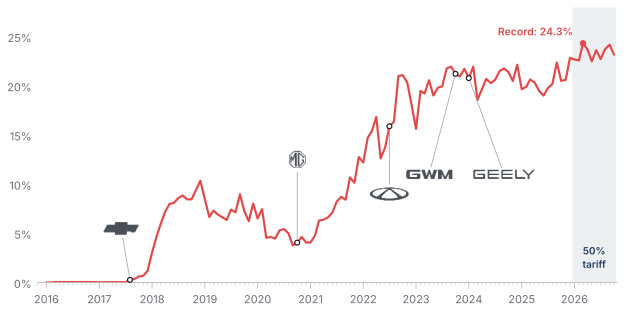

<sub>Source: INEGI, RAIAVL, Jan 2016 to Oct 2026. Brands that don't report, like BYD, are not included. Logos: Wikimedia, listed in logos/SOURCES.md.</sub>

In [3]:
RED, NAVY, INK, MUTED, GRID = "#e34948", "#1F3A5F", "#16181D", "#6b6f76", "#e6e4dd"
plt.rcParams.update({"font.family": "Inter", "font.size": 11,
                     "axes.edgecolor": "#b9b7b0", "xtick.color": MUTED, "ytick.color": MUTED,
                     "lines.solid_joinstyle": "round", "lines.solid_capstyle": "round"})   # smooth corners on the line

fig, ax = plt.subplots(figsize=(9, 4.3), dpi=110)   # 9 inches wide fits a notebook column
fig.subplots_adjust(left=0.065, right=0.96, top=0.97, bottom=0.08)

# Months under the 50% tariff, shaded
start = pd.Timestamp(f"{this_year}-01-01")
ax.axvspan(start - pd.Timedelta(days=15), LAST + pd.Timedelta(days=15), color=NAVY, alpha=0.08, lw=0)
ax.text(start + (LAST - start) / 2, 0.012, "50%\ntariff", color=NAVY, fontsize=10, fontweight="semibold",
        ha="center", va="bottom", linespacing=1.1)

# The China-made share, with the record month marked
ax.plot(share.index, share.values, color=RED, lw=2.2)
ax.scatter([record], [share[record]], color=RED, s=30, zorder=3)
ax.annotate(f"Record: {share[record]:.1%}", xy=(record, share[record]), xytext=(-10, 8),
            textcoords="offset points", ha="right", color=RED, fontsize=10.5, fontweight="semibold")

# Logos where brands first appear: GM's China-built Chevrolets, then the four biggest Chinese brands
chinese_brands = sales[(sales["origin_block"] == "China") & (sales["brand_home"] == "China")]
assert set(chinese_brands.groupby("brand")["units"].sum().nlargest(4).index) == {"MG", "Geely", "Chirey", "Great Wall"}
first = chinese_brands.groupby("brand")["date"].min()
LOGOS = [  # logo file, month it marks, logo height in points, where the logo sits (month, share)
    ("chevrolet", pd.Timestamp("2017-08-01"), 13, "2017-06", 0.055),  # GM's China-made sales jump from about 40 to 340 a month
    ("mg", first["MG"], 17, "2020-10", 0.125),
    ("chirey", first["Chirey"], 13, "2022-07", 0.09),
    ("gwm", first["Great Wall"], 10, "2023-04", 0.11),
    ("geely", first["Geely"], 9, "2024-09", 0.11),
]
for name, month, height, x, y in LOGOS:
    logo = plt.imread(f"logos/{name}.png")
    spot = (pd.Timestamp(x), y)
    ax.annotate("", xy=(month, share[month]), xytext=spot,
                arrowprops=dict(arrowstyle="-", color="#a7a59e", lw=0.8, shrinkA=height * 0.75, shrinkB=4))
    ax.add_artist(AnnotationBbox(OffsetImage(logo, zoom=height / logo.shape[0]), spot, frameon=False))
    ax.scatter([month], [share[month]], s=24, color="white", edgecolor=INK, linewidth=1.2, zorder=4)

# Axes: percent ticks, years and months, no grid lines
ax.set_ylim(0, 0.28)
ax.set_xlim(pd.Timestamp("2015-11-01"), LAST + pd.Timedelta(days=20))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xticks(pd.date_range("2016-01-01", f"{this_year}-01-01", freq="YS"))
ax.set_xticklabels(range(2016, this_year + 1))
ax.xaxis.set_minor_locator(mdates.MonthLocator())                      # a small tick for every month
ax.tick_params(axis="x", which="major", length=6, color="#b9b7b0", pad=4)  # longer tick at each January
ax.tick_params(axis="x", which="minor", length=3, color="#cfcdc6")
ax.tick_params(axis="y", length=0, pad=6)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

# Title and subtitle as real text above the chart, source below it
display(Markdown("### Even with a 50% tariff, China-made cars hit a record share of sales in Mexico\n"
                 "Share of new cars sold in Mexico that were built in China, by month. Logos mark when GM's China-built Chevrolets "
                 "and the four biggest Chinese brands first appear in the data."))
fig.savefig("china_made_share.png", dpi=300, facecolor="white")
plt.show()
display(Markdown(f"<sub>Source: INEGI, RAIAVL, Jan 2016 to {LAST:%b %Y}. Brands that don't report, like BYD, are not included. Logos: Wikimedia, listed in logos/SOURCES.md.</sub>"))

## The same chart, one observation at a time

Each piece below is the same chart. The whole line stays in light gray for context, and the stretch being discussed is in red, with one sentence that says what it shows. Each chart is also saved as an image in `story/` for slides (titles are text here, so type them on the slide).

Every piece shows the share of new cars sold in Mexico that were built in China, by month. Source: INEGI, RAIAVL. Brands that don't report, like BYD, are not included.

In [4]:
# Facts behind the titles that name brands, checked here so the titles stay true
china_sales = sales[sales["origin_block"] == "China"]
by_brand = china_sales.groupby([china_sales["date"].dt.year, "brand"])["units"].sum().unstack(fill_value=0)

gm_part_2018 = by_brand.loc[2018, "GM"] / by_brand.loc[2018].sum()
growth = (by_brand.loc[2022] - by_brand.loc[2020]).nlargest(2)   # brands that added the most China-made cars

print(f"2018: GM sold {gm_part_2018:.0%} of the China-made cars")
print(f"GM China-made cars: {by_brand.loc[2018, 'GM']:,} in 2018, {by_brand.loc[2020, 'GM']:,} in 2020")
print("Most added from 2020 to 2022:", ", ".join(f"{b} +{n:,}" for b, n in growth.items()))

assert gm_part_2018 > 0.5                                         # "GM began selling China-built Chevrolets"
assert by_brand.loc[2020, "GM"] < by_brand.loc[2018, "GM"] / 2    # "as GM sold fewer China-built cars"
assert list(growth.index) == ["GM", "MG"]                          # "led by GM and MG"


2018: GM sold 85% of the China-made cars
GM China-made cars: 93,543 in 2018, 37,597 in 2020
Most added from 2020 to 2022: GM +70,175, MG +47,402


In [5]:
LIGHT = "#d9d7d0"
N = 8                        # number of pieces
Path("story").mkdir(exist_ok=True)


def piece(n, title, red, labels=(), compare=None, average=None, tariff=False):
    # One piece of the story: the whole line in light gray, the stretch being discussed in red.
    # labels: (month, text, color, dx, dy, dot) placed next to that month's point.
    fig, ax = plt.subplots(figsize=(9, 3.9), dpi=110)
    fig.subplots_adjust(left=0.07, right=0.96, top=0.96, bottom=0.09)

    if tariff:   # months under the 50% tariff
        ax.axvspan(start - pd.Timedelta(days=15), LAST + pd.Timedelta(days=15), color=NAVY, alpha=0.08, lw=0)
        ax.text(start + (LAST - start) / 2, 0.012, "50%\ntariff", color=NAVY, fontsize=9.5,
                fontweight="semibold", ha="center", va="bottom", linespacing=1.1)
    ax.plot(share, color=LIGHT, lw=1.8)                                  # the whole line, for context
    if compare:
        ax.plot(share[compare[0]:compare[1]], color=MUTED, lw=2.2)       # a stretch to compare against
    ax.plot(share[red[0]:red[1]], color=RED, lw=2.4)                     # the stretch this piece is about
    if average is not None:
        ax.hlines(average, pd.Timestamp(red[0]), pd.Timestamp(red[1]), color=INK, lw=1, ls=(0, (4, 3)))
        ax.text(pd.Timestamp(red[1]) + pd.Timedelta(days=20), average - 0.004, f"average\n{average:.1%}",
                color=INK, fontsize=10, va="top", linespacing=1.1)
    for month, text, color, dx, dy, dot in labels:
        m = pd.Timestamp(month)
        if dot:
            ax.scatter([m], [share[m]], color=color, s=28, zorder=3)
        ax.annotate(text, xy=(m, share[m]), xytext=(dx, dy), textcoords="offset points", color=color,
                    ha="right" if dx < 0 else "left" if dx > 0 else "center", va="center",
                    fontsize=10.5, fontweight="semibold", linespacing=1.15)

    # same axes on every piece, so only the red part changes
    ax.set_ylim(0, 0.28)
    ax.set_xlim(pd.Timestamp("2015-11-01"), LAST + pd.Timedelta(days=20))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_yticks([0, 0.05, 0.10, 0.15, 0.20, 0.25])
    ax.set_xticks(pd.date_range("2016-01-01", f"{this_year}-01-01", freq="YS"))
    ax.set_xticklabels(range(2016, this_year + 1))
    ax.xaxis.set_minor_locator(mdates.MonthLocator())                  # a small tick for every month
    ax.tick_params(axis="x", which="major", length=6, color="#b9b7b0", pad=4)
    ax.tick_params(axis="x", which="minor", length=3, color="#cfcdc6")
    ax.tick_params(axis="y", length=0, pad=6)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

    display(Markdown(f"Part {n} of {N}\n### {title}"))          # the title as real text, above the chart
    fig.savefig(f"story/{n:02d}.png", dpi=300, facecolor="white")
    plt.show()

Part 1 of 8
### Until 2017, almost no car sold in Mexico was made in China

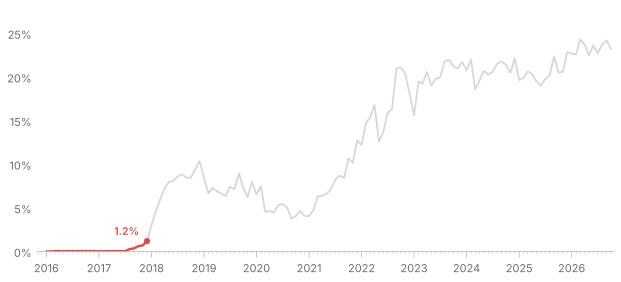

In [6]:
piece(1, "Until 2017, almost no car sold in Mexico was made in China",
      red=("2016-01", "2017-12"),
      labels=[("2017-12", f"{share['2017-12-01']:.1%}", RED, -8, 10, True)])

Part 2 of 8
### In 2018 GM began selling China-built Chevrolets, and the share reached 10%

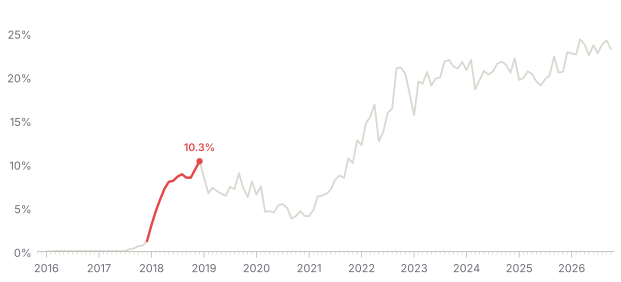

In [7]:
piece(2, f"In 2018 GM began selling China-built Chevrolets, and the share reached {share['2018-12-01']:.0%}",
      red=("2017-12", "2018-12"),
      labels=[("2018-12", f"{share['2018-12-01']:.1%}", RED, 0, 14, True)])

Part 3 of 8
### Then it slipped back to 4%, as GM sold fewer China-built cars

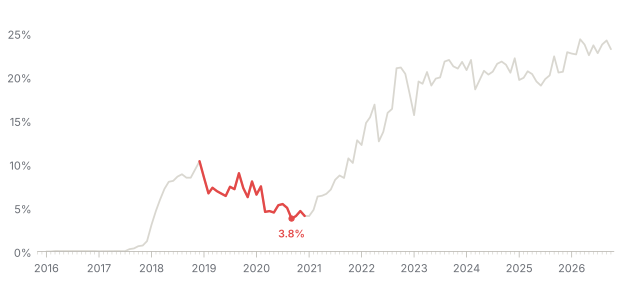

In [8]:
low = share["2019":"2020"].idxmin()
piece(3, f"Then it slipped back to {share[low]:.0%}, as GM sold fewer China-built cars",
      red=("2018-12", "2020-12"),
      labels=[(low, f"{share[low]:.1%}", RED, 0, -15, True)])

Part 4 of 8
### Then it jumped from 4% to 21% in about two years, led by GM and MG

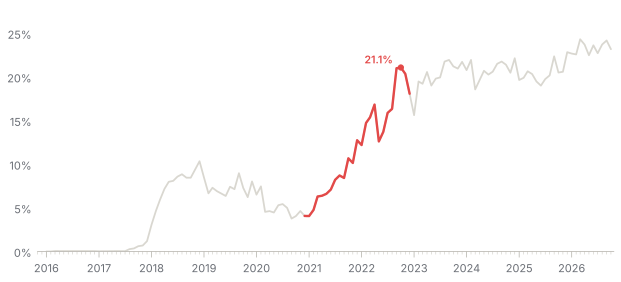

In [9]:
peak = share["2021":"2022"].idxmax()
piece(4, f"Then it jumped from {share[low]:.0%} to {share[peak]:.0%} in about two years, led by GM and MG",
      red=("2020-12", "2022-12"),
      labels=[(peak, f"{share[peak]:.1%}", RED, -8, 8, True)])

Part 5 of 8
### For the next three years it held steady at about 20%

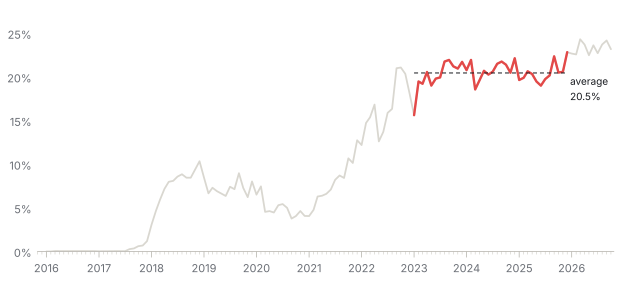

In [10]:
piece(5, f"For the next three years it held steady at about {plateau:.0%}",
      red=("2023-01", "2025-12"), average=plateau)

Part 6 of 8
### From March 2025 the line leaves out Chirey and Omoda, which stopped reporting

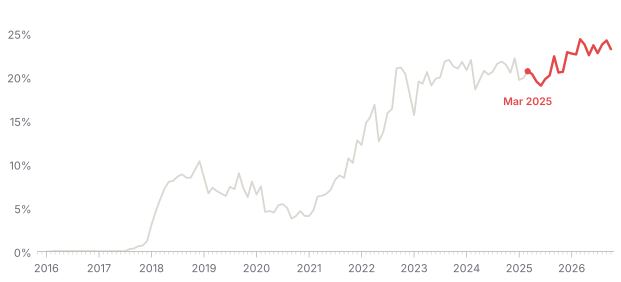

In [11]:
piece(6, "From March 2025 the line leaves out Chirey and Omoda, which stopped reporting",
      red=("2025-03", LAST),
      labels=[("2025-03", "Mar 2025", RED, 0, -30, True)])

Part 7 of 8
### Since the 50% tariff began, every month has beaten the same month of 2025

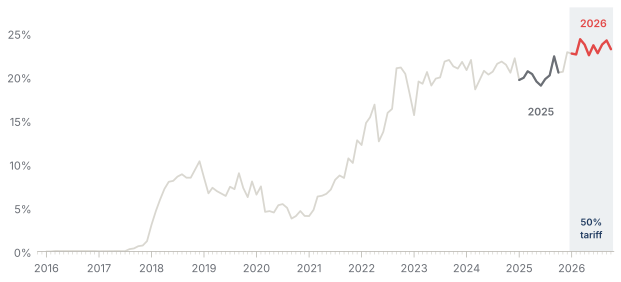

In [12]:
piece(7, f"Since the 50% tariff began, every month has beaten the same month of {last_year}",
      red=(f"{this_year}-01", LAST), compare=(f"{last_year}-01", f"{last_year}-{LAST.month:02d}"), tariff=True,
      labels=[(f"{last_year}-06", str(last_year), MUTED, 0, -26, False),
              (f"{this_year}-06", str(this_year), RED, 0, 22, False)])

Part 8 of 8
### March 2026 set the record: 24.3% of cars sold were made in China

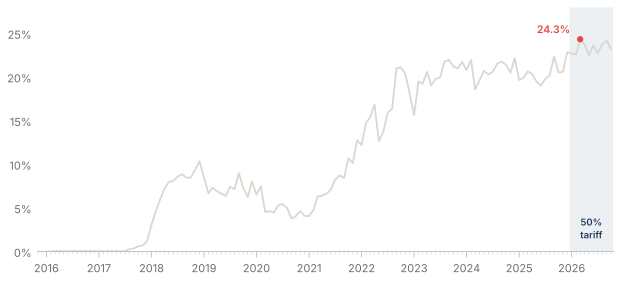

In [13]:
piece(8, f"{record:%B %Y} set the record: {share[record]:.1%} of cars sold were made in China",
      red=(record, record), tariff=True,
      labels=[(record, f"{share[record]:.1%}", RED, -10, 10, True)])

## What it means for the Subsecretaría

- **The tariff hasn't cut the China-made share yet.** It went from a flat 20% in 2023–2025 to 23% in 2026, and that is without Chirey and Omoda, which stopped reporting in March 2025.
- **The registry counts sales, not imports.** Secretaría de Economía figures show imports of Chinese cars fell 31.1% in the first half of 2026 (El Economista, via La República, 31 Aug 2026). Cars shipped before January are still being sold, so the tariff's effect should show up later.
- **Decision:** don't judge the tariff on 2026 sales. Review it with the twelve months to mid-2027, once that stock has been sold, and ask BYD to report to the registry so the review covers the biggest Chinese brand.